# Comparación final de modelos

Junto los modelos de los tres miembros del grupo. Todos usan la misma partición, los mismos folds, las mismas métricas y el mismo pipeline (`src/utils/modelado.py`), así que se pueden comparar fold a fold.

El orden del notebook es el que exige evitar la fuga de datos: comparo y elijo **solo con validación cruzada** (apartados 1-5) y dejo la decisión escrita. Después evalúo en test **una sola vez**, con el modelo elegido (apartado 6).

## 0. Criterio de elección (fijado antes de mirar el test)

1. **F1 macro** en validación.
2. Si hay empate (el F1 queda dentro de la desviación entre folds del mejor), **recall de riesgo alto**.
3. Si sigue el empate: **menos errores graves** (riesgo alto clasificado como bajo), **menos sobreajuste** y, entre modelos distintos, **el más sencillo e interpretable**.

La comparación fold a fold sirven de apoyo, no sustituyen al criterio.

In [1]:
from utils import modelado as mod, constantes as cte
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, get_scorer
from sklearn.model_selection import cross_val_predict, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

%matplotlib inline
pd.set_option("display.max_colwidth", None)

# misma partición que el resto de notebooks; X_test solo se usa en el apartado 7
X_train, X_test, y_train, y_test = mod.cargar_datos()

## 1. Configuración elegida por cada uno

Cada notebook guardó en `resultados/<modelo>.csv` los mejores hiperparámetros. Aquí solo hace falta el modelo base y el balanceo que eligió cada uno; los hiperparámetros se leen del CSV, así no se copian a mano ni se quedan desactualizados.

In [2]:
# modelo base y balanceo elegidos en cada notebook (los hiperparámetros salen de resultados/<nombre>.csv)
configuracion = {
    # Pablo (modelos_pablo.ipynb)
    "logistica": (LogisticRegression(solver="saga", max_iter=5000, random_state=cte.semilla), "class_weight"),
    "naive_bayes": (GaussianNB(), "smotenc"),
    "hist_gradient_boosting": (HistGradientBoostingClassifier(random_state=cte.semilla), "class_weight"),
    # Rodrigo (modelos_rodrigo.ipynb)
    "arbol": (DecisionTreeClassifier(random_state=cte.semilla), "smotenc"),
    "knn": (KNeighborsClassifier(), "smotenc"),
    "random_forest": (RandomForestClassifier(random_state=cte.semilla), "class_weight"),
    # Enzo (modelos_enzo.ipynb)
    "lda": (LinearDiscriminantAnalysis(), "smotenc"),
    "svm": (SVC(), "class_weight"),
    # el voting combina cuatro pipelines, cada uno con su propio balanceo (ver reconstruir)
    "voting": (None, "el de cada modelo"),
}


def mejores_parametros(nombre):
    """Hiperparámetros guardados por guardar_resultados (texto -> diccionario)."""
    texto = pd.read_csv(mod.RUTA_RESULTADOS / f"{nombre}.csv")["mejores_parametros"].iloc[0]
    return ast.literal_eval(texto)


def reconstruir(nombre):
    """Pipeline sin entrenar con el balanceo y los hiperparámetros elegidos."""
    if nombre == "voting":
        # mismos modelos y mismo orden que en modelos_enzo.ipynb: los pesos van por posición
        svm = reconstruir("svm").set_params(modelo__probability=True, modelo__random_state=cte.semilla)  # soft necesita probabilidades
        estimadores = [("lda", reconstruir("lda")), ("svm", svm),
                       ("rf", reconstruir("random_forest")), ("lr", reconstruir("logistica"))]
        return VotingClassifier(estimadores).set_params(**mejores_parametros("voting"))
    modelo, balanceo = configuracion[nombre]
    return mod.crear_pipeline(modelo, balanceo).set_params(**mejores_parametros(nombre))


pipelines = {nombre: reconstruir(nombre) for nombre in configuracion}
balanceo = pd.Series({nombre: b or "sin_balanceo" for nombre, (_, b) in configuracion.items()}, name="balanceo")
balanceo.to_frame()

,balanceo
logistica,class_weight
naive_bayes,smotenc
hist_gradient_boosting,class_weight
arbol,smotenc
knn,smotenc
random_forest,class_weight
lda,smotenc
svm,class_weight
voting,el de cada modelo


## 2. Comprobación: los modelos reconstruidos dan lo mismo que en cada notebook

Si alguien cambió su modelo y no volvió a guardar el CSV, o el balanceo de la tabla anterior no es el bueno, aquí sale una diferencia.

In [3]:
# misma validación cruzada que en cada notebook: mismos folds (mod.validador) y mismas métricas (mod.metricas).
# solo para comprobar que el modelo reconstruido da lo mismo que su CSV
validacion = {nombre: cross_validate(pipeline, X_train, y_train, cv=mod.validador, scoring=mod.metricas,
                                     return_train_score=True, n_jobs=-1)
              for nombre, pipeline in pipelines.items()}

comprobadas = ["f1_macro", "recall_alto"]
filas = {}
for nombre, r in validacion.items():
    guardado = pd.read_csv(mod.RUTA_RESULTADOS / f"{nombre}.csv").iloc[0]                    # media guardada
    folds = pd.read_csv(mod.RUTA_RESULTADOS / f"{nombre}_folds.csv", index_col="fold")        # nota de cada fold
    fila = {}
    for m in comprobadas:
        fila[f"{m}_csv"] = guardado[f"{m}_val"]
        fila[f"{m}_reconstruido"] = r[f"test_{m}"].mean()       # en cross_validate, "test" es el fold de validación
        # coincide solo si coinciden los 5 folds, no basta la media (así se comprueba también que los folds son los mismos)
        fila[f"{m}_coincide"] = np.allclose(r[f"test_{m}"], folds[m], atol=1e-6)
    filas[nombre] = fila

comprobacion = pd.DataFrame.from_dict(filas, orient="index")
columnas_ok = [f"{m}_coincide" for m in comprobadas]

# verde si coincide, rojo si no
display(comprobacion.style
        .format(precision=4, subset=comprobacion.columns.difference(columnas_ok))
        .map(lambda ok: f"background-color: {'#c6efce' if ok else '#ffc7ce'}", subset=columnas_ok))

# si algo no cuadra, el notebook se para aquí y no se compara con un modelo equivocado
assert comprobacion[columnas_ok].all().all(), "Algún modelo reconstruido no coincide con su CSV"


,f1_macro_csv,f1_macro_reconstruido,f1_macro_coincide,recall_alto_csv,recall_alto_reconstruido,recall_alto_coincide
logistica,0.6513,0.6513,True,0.7479,0.7479,True
naive_bayes,0.6265,0.6265,True,0.7506,0.7506,True
hist_gradient_boosting,0.6452,0.6452,True,0.7229,0.7229,True
arbol,0.5414,0.5414,True,0.5956,0.5956,True
knn,0.5896,0.5896,True,0.7727,0.7727,True
random_forest,0.6482,0.6482,True,0.7229,0.7229,True
lda,0.6363,0.6363,True,0.7589,0.7589,True
svm,0.6481,0.6481,True,0.7284,0.7284,True
voting,0.6697,0.6697,True,0.7533,0.7533,True


## 3. Resultados en validación

Una fila por modelo con su mejor configuración, más el suelo (predecir siempre riesgo bajo) como referencia.

In [4]:
# suelo: no tiene CSV propio, se calcula aquí con el mismo validador
suelo = mod.crear_busqueda(mod.crear_pipeline(DummyClassifier(strategy="most_frequent"), None), {}).fit(X_train, y_train)

resultados = pd.concat([pd.read_csv(mod.RUTA_RESULTADOS / f"{n}.csv", index_col="modelo") for n in configuracion]
                       + [mod.tabla_resultados(suelo, "suelo")])
resultados["balanceo"] = balanceo
resultados.loc["suelo", "balanceo"] = "sin_balanceo"

columnas = ["balanceo", "f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std",
            "precision_alto_val", "f1_macro_train", "diferencia_train_val"]
resultados = resultados.sort_values("f1_macro_val", ascending=False)
resultados[columnas].round(3)

,balanceo,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,f1_macro_train,diferencia_train_val
modelo,,,,,,,,
voting,el de cada modelo,0.670,0.029,0.753,0.041,0.677,0.916,0.246
logistica,class_weight,0.651,0.034,0.748,0.059,0.631,0.675,0.024
random_forest,class_weight,0.648,0.035,0.723,0.032,0.646,0.997,0.348
svm,class_weight,0.648,0.018,0.728,0.045,0.644,0.833,0.185
hist_gradient_boosting,class_weight,0.645,0.027,0.723,0.032,0.642,0.934,0.289
lda,smotenc,0.636,0.028,0.759,0.052,0.611,0.658,0.021
naive_bayes,smotenc,0.627,0.029,0.751,0.052,0.603,0.650,0.023
knn,smotenc,0.590,0.020,0.773,0.069,0.562,0.635,0.045
arbol,smotenc,0.541,0.033,0.596,0.020,0.504,0.867,0.326


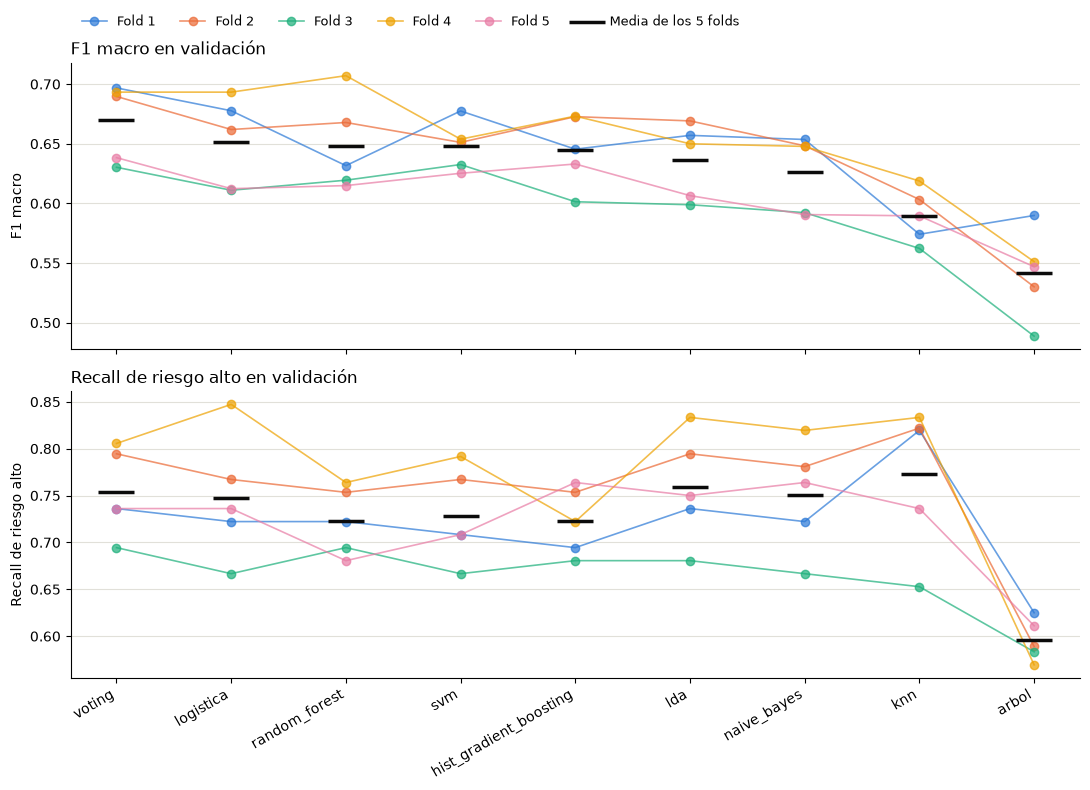

In [5]:
folds = {n: pd.read_csv(mod.RUTA_RESULTADOS / f"{n}_folds.csv", index_col="fold") for n in configuracion}
orden = [n for n in resultados.index if n in folds]

# una línea por fold: los 5 folds son los mismos pacientes en todos los modelos, así que unirlos
# muestra si un fold es difícil para todos (líneas paralelas) o si el ranking cambia de fold a fold (se cruzan)
metricas_grafica = {"f1_macro": "F1 macro", "recall_alto": "Recall de riesgo alto"}
colores_fold = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # un color fijo por fold
x = np.arange(len(orden))   # posición de cada modelo en el eje x, en el orden de la tabla del apartado 3

# un panel por métrica con su propio eje y (no dos escalas en el mismo gráfico)
fig, ejes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for eje, (metrica, titulo) in zip(ejes, metricas_grafica.items()):
    tabla = pd.DataFrame({n: folds[n][metrica] for n in orden})   # filas: folds; columnas: modelos en orden
    for (k, fila), color in zip(tabla.iterrows(), colores_fold):
        eje.plot(x, fila, color=color, linewidth=1.2, alpha=0.7, marker="o", markersize=6, label=f"Fold {k + 1}")
    # la media de los 5 folds es el valor *_val de la tabla del apartado 3
    eje.scatter(x, tabla.mean(), marker="_", s=700, linewidths=2.5, color="#0b0b0b", zorder=3,
                label="Media de los 5 folds")
    eje.set_title(f"{titulo} en validación", loc="left", fontsize=12)
    eje.set_ylabel(titulo)
    eje.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    eje.set_axisbelow(True)                       # la rejilla queda detrás de los puntos
    eje.spines[["top", "right"]].set_visible(False)

ejes[-1].set_xticks(x, orden, rotation=30, ha="right")
ejes[0].legend(ncol=6, loc="lower left", bbox_to_anchor=(0, 1.08), frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

- **El fold pesa más que el modelo:** En F1, los folds 3 y 5 quedan por debajo para casi todos los modelos, y los folds 1, 2 y 4 por encima. En recall pasa lo mismo: el fold 4 suele salir alto y el fold 3 bajo.

- **Voting tiene la mejor media, pero no gana en todos los folds:** En el fold 3 el SVM lo supera por poco, y en el fold 4 lo supera el random forest y lo iguala la logística.

- **Logística, random forest, SVM y HGB están mezclados:** Sus líneas se cruzan y las medias se separan menos que la variación entre folds, así que lo trato como un empate (apartado 5).

- **KNN tiene el mejor recall de riesgo alto pero un F1 bajo**: elegir solo por recall premia al que dice «riesgo alto» de más.

- **El árbol queda por debajo de todos en recall en todos los folds**, y en F1 en todos menos el fold 1.

## 4. Preprocesamiento × modelo

F1 macro y, entre paréntesis, recall de riesgo alto en validación de cada modelo con cada balanceo (de los `<modelo>_preprocesamientos.csv`). Es la tabla donde los preprocesamientos se comparan con todos los modelos.

In [6]:
versiones = pd.concat([pd.read_csv(p) for p in sorted(mod.RUTA_RESULTADOS.glob("*_preprocesamientos.csv"))])
versiones["celda"] = versiones["f1_macro_val"].map("{:.3f}".format) + " (" + \
                     versiones["recall_alto_val"].map("{:.2f}".format) + ")"
tabla_preprocesamientos = versiones.pivot(index="modelo", columns="preprocesamiento", values="celda") \
    .reindex(columns=["sin_balanceo", "class_weight", "smotenc", "tomek", "enn"]).fillna("—")
# añado qué versión eligió cada uno
tabla_preprocesamientos["elegido"] = balanceo.reindex(tabla_preprocesamientos.index)
tabla_preprocesamientos

preprocesamiento,sin_balanceo,class_weight,smotenc,tomek,enn,elegido
modelo,,,,,,
arbol,0.545 (0.50),0.532 (0.60),0.541 (0.60),0.540 (0.52),—,smotenc
hist_gradient_boosting,0.642 (0.66),0.645 (0.72),0.638 (0.72),0.644 (0.71),—,class_weight
knn,0.537 (0.41),—,0.590 (0.77),0.549 (0.49),—,smotenc
lda,0.660 (0.68),—,0.636 (0.76),0.647 (0.72),0.567 (0.82),smotenc
logistica,0.647 (0.67),0.651 (0.75),0.637 (0.75),0.636 (0.70),—,class_weight
naive_bayes,0.643 (0.68),—,0.627 (0.75),0.625 (0.70),—,smotenc
random_forest,0.611 (0.56),0.648 (0.72),0.627 (0.69),0.609 (0.68),—,class_weight
svm,0.649 (0.68),0.648 (0.73),0.636 (0.73),0.643 (0.70),0.556 (0.81),class_weight


## 5. Aplicar el criterio:

1. **F1 macro:** Empatan con el mejor los modelos cuyo F1 queda dentro de la desviación entre folds del mejor.

2. Entre los empatados, **recall de riesgo alto**, con la misma regla de empate.

3. Si sigue el empate, **errores graves** (pacientes de riesgo alto clasificados como bajo en validación cruzada), después **sobreajuste** y, por último, **sencillez**.

In [7]:
# 1.er paso: empatan con el mejor los modelos cuyo F1 queda dentro de su desviación entre folds
mejor = resultados.iloc[0]
umbral_f1 = mejor["f1_macro_val"] - mejor["f1_macro_val_std"]
resultados["empata_en_f1"] = resultados["f1_macro_val"] >= umbral_f1

# 2.º paso: entre los empatados, el recall de riesgo alto (con el mismo criterio de empate)
empatados = resultados[resultados["empata_en_f1"]]
mejor_recall = empatados.loc[empatados["recall_alto_val"].idxmax()]
umbral_recall = mejor_recall["recall_alto_val"] - mejor_recall["recall_alto_val_std"]
resultados["empata_en_recall"] = resultados["empata_en_f1"] & (resultados["recall_alto_val"] >= umbral_recall)

print(f"Paso 1: empatan en F1 los modelos con F1 >= {umbral_f1:.3f} "
      f"({mejor.name}: {mejor['f1_macro_val']:.3f} ± {mejor['f1_macro_val_std']:.3f})")
print(f"Paso 2: empatan en recall de alto los que tienen >= {umbral_recall:.3f} "
      f"({mejor_recall.name}: {mejor_recall['recall_alto_val']:.3f} ± {mejor_recall['recall_alto_val_std']:.3f})")
resultados.loc[resultados.index != "suelo", columnas + ["empata_en_f1", "empata_en_recall"]].round(3)

Paso 1: empatan en F1 los modelos con F1 >= 0.641 (voting: 0.670 ± 0.029)
Paso 2: empatan en recall de alto los que tienen >= 0.712 (voting: 0.753 ± 0.041)


,balanceo,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,f1_macro_train,diferencia_train_val,empata_en_f1,empata_en_recall
modelo,,,,,,,,,,
voting,el de cada modelo,0.670,0.029,0.753,0.041,0.677,0.916,0.246,True,True
logistica,class_weight,0.651,0.034,0.748,0.059,0.631,0.675,0.024,True,True
random_forest,class_weight,0.648,0.035,0.723,0.032,0.646,0.997,0.348,True,True
svm,class_weight,0.648,0.018,0.728,0.045,0.644,0.833,0.185,True,True
hist_gradient_boosting,class_weight,0.645,0.027,0.723,0.032,0.642,0.934,0.289,True,True
lda,smotenc,0.636,0.028,0.759,0.052,0.611,0.658,0.021,False,False
naive_bayes,smotenc,0.627,0.029,0.751,0.052,0.603,0.650,0.023,False,False
knn,smotenc,0.590,0.020,0.773,0.069,0.562,0.635,0.045,False,False
arbol,smotenc,0.541,0.033,0.596,0.020,0.504,0.867,0.326,False,False


**3.er paso: errores graves.** Con `cross_val_predict`, a cada paciente del train lo predice el modelo del fold en el que estaba en validación (sin tocar el test). Lo hago con los modelos que siguen empatados.

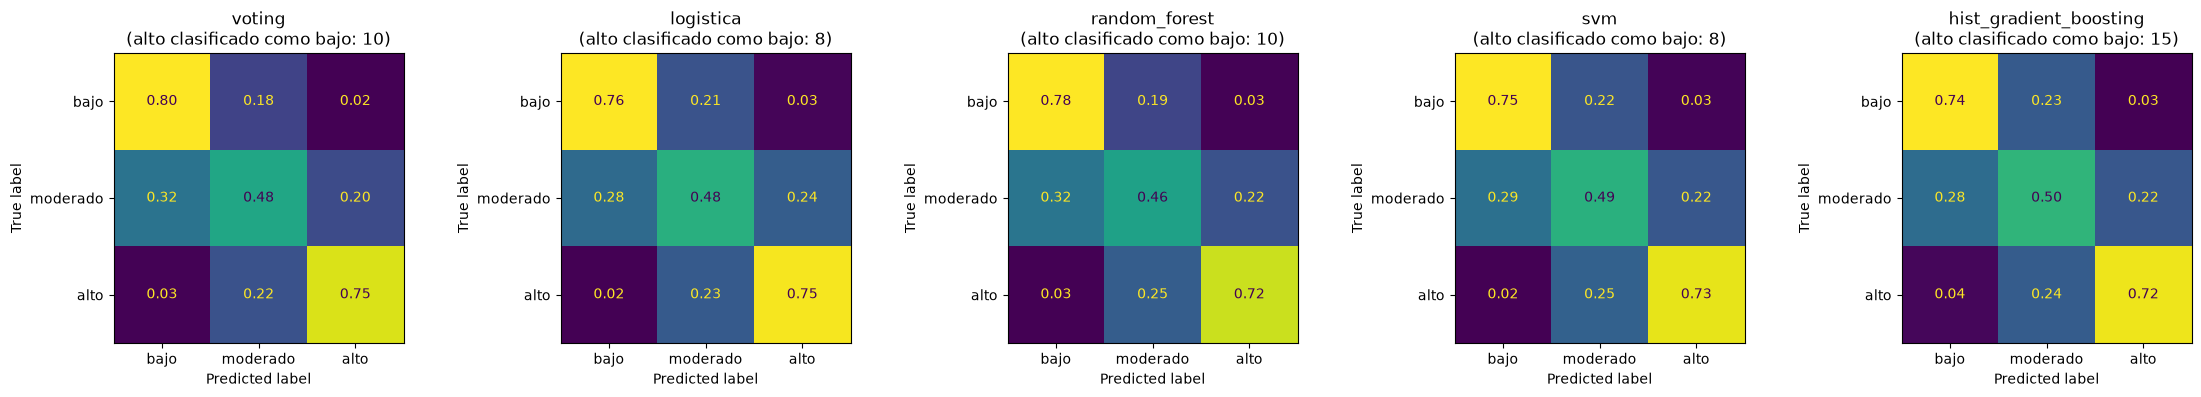

,balanceo,f1_macro_val,recall_alto_val,precision_alto_val,alto_como_bajo,diferencia_train_val
modelo,,,,,,
logistica,class_weight,0.651,0.748,0.631,8.0,0.024
svm,class_weight,0.648,0.728,0.644,8.0,0.185
voting,el de cada modelo,0.670,0.753,0.677,10.0,0.246
random_forest,class_weight,0.648,0.723,0.646,10.0,0.348
hist_gradient_boosting,class_weight,0.645,0.723,0.642,15.0,0.289


In [8]:
finalistas = list(resultados.index[resultados["empata_en_recall"]])
fig, axes = plt.subplots(1, len(finalistas), figsize=(4.5 * len(finalistas), 4))
for ax, nombre in zip(np.atleast_1d(axes), finalistas):
    y_pred = cross_val_predict(pipelines[nombre], X_train, y_train, cv=mod.validador, n_jobs=-1)
    resultados.loc[nombre, "alto_como_bajo"] = ((y_train == 2) & (y_pred == 0)).sum()
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred, display_labels=["bajo", "moderado", "alto"],
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(f"{nombre}\n(alto clasificado como bajo: {resultados.loc[nombre, 'alto_como_bajo']:.0f})")
plt.tight_layout()
plt.show()

resultados.loc[finalistas, ["balanceo", "f1_macro_val", "recall_alto_val", "precision_alto_val",
                            "alto_como_bajo", "diferencia_train_val"]].sort_values("alto_como_bajo").round(3)

**Decisión**:

- **Paso 1**: empatan en F1 el voting (0,670 ± 0,029), la logística, el random forest, el SVM y el HGB (F1 ≥ 0,641). LDA, Naive Bayes, kNN y el árbol quedan fuera.

- **Paso 2**: los cinco siguen empatados en recall de riesgo alto (≥ 0,712).

- **Paso 3**: la logística y el SVM son los que menos pacientes de riesgo alto clasifican como bajo (8 cada uno, frente a 10 del voting y del random forest y 15 del HGB). Entre esos dos, la logística sobreajusta mucho menos (0,024 frente a 0,185). Además es el modelo más sencillo e interpretable (coeficientes en el apartado 3 de `modelos_pablo.ipynb`)

- **Modelo elegido: regresión logística**, con `class_weight`, `C = 0,1` y regularización L2 (`l1_ratio = 0`).



## 6. Evaluación final en test

Entreno el modelo elegido con **todo** el train (el pipeline vuelve a calcular la mediana, el escalado y el balanceo solo con el train) y lo evalúo en el test, que no se ha usado hasta ahora. El resultado no cambia la decisión del apartado 5: solo dice cuánto se parece el rendimiento real al estimado con validación cruzada.

              precision    recall  f1-score   support

        bajo      0.862     0.774     0.816       226
    moderado      0.533     0.533     0.533       135
        alto      0.619     0.778     0.690        90

    accuracy                          0.703       451
   macro avg      0.672     0.695     0.680       451
weighted avg      0.715     0.703     0.706       451



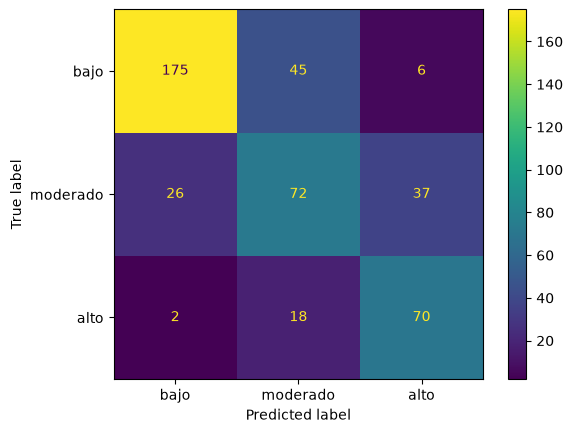

In [9]:
modelo_final = pipelines["logistica"].fit(X_train, y_train)
mod.evaluar_test(modelo_final, X_test, y_test)

In [10]:
# validación cruzada (estimación) frente a test (rendimiento con pacientes nuevos)
y_pred_test = modelo_final.predict(X_test)
test_vs_val = pd.DataFrame({
    "validacion": [resultados.loc["logistica", f"{m}_val"] for m in mod.metricas],
    "desviacion_folds": [resultados.loc["logistica", f"{m}_val_std"] for m in mod.metricas],
    "test": [get_scorer(s)(modelo_final, X_test, y_test) for s in mod.metricas.values()],
}, index=list(mod.metricas))
test_vs_val["diferencia"] = test_vs_val["test"] - test_vs_val["validacion"]
print("Riesgo alto clasificado como bajo en test:", ((y_test == 2) & (y_pred_test == 0)).sum(), "de", (y_test == 2).sum())
test_vs_val.round(3)

Riesgo alto clasificado como bajo en test: 2 de 90


,validacion,desviacion_folds,test,diferencia
f1_macro,0.651,0.034,0.680,0.028
precision_macro,0.644,0.033,0.672,0.027
recall_macro,0.663,0.034,0.695,0.032
recall_alto,0.748,0.059,0.778,0.030
precision_alto,0.631,0.055,0.619,-0.012


In [11]:
resultados.to_csv(mod.RUTA_RESULTADOS / "comparacion_final.csv")

**Conclusión**

- **El test confirma lo estimado con validación cruzada.** El F1 macro en test es 0,680, frente a 0,651 ± 0,034 en validación, y el recall de riesgo alto es 0,778, frente a 0,748 ± 0,059. Todas las métricas quedan a menos de una desviación entre folds de su estimación (la mayor diferencia es de +0,032), así que no lo interpreto como una mejora real, sino como la variación normal de una partición de 451 pacientes. Lo importante es que el rendimiento no cae: el modelo no está sobreajustado y no hay señales de fuga de datos.

- **El error más grave sigue siendo muy poco frecuente.** Solo 2 de los 90 pacientes de riesgo alto del test se clasifican como riesgo bajo (2,2 %), la misma proporción que en validación cruzada (8 de 361). De los 20 que el modelo no detecta como riesgo alto, 18 los clasifica como moderado, no como bajo.

- **El precio son las falsas alarmas.** La precisión de riesgo alto es 0,619: de los 113 pacientes que el modelo marca como riesgo alto, 43 no lo son. Es la consecuencia esperada de `class_weight`, que da más peso a no dejar escapar el riesgo alto aunque se avise de más. En este problema prefiero una alarma de más a un paciente de riesgo alto clasificado como bajo.

- **El riesgo moderado sigue siendo la clase difícil.** Su F1 en test es 0,533, frente a 0,816 en riesgo bajo y 0,690 en riesgo alto. Es lo mismo que vimos en validación con todos los modelos: el moderado se solapa con las otras dos clases, y el límite lo ponen los datos más que el modelo elegido.

- **Resumen:** la regresión logística con `class_weight`, `C = 0,1` y regularización L2 rinde en pacientes nuevos lo que esperábamos, comete muy pocos errores graves y es interpretable. Es el modelo que proponemos.
